# 4.1 Охлаждение: Эйлер и RK4

# 4.1 冷却过程：欧拉法与 RK4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (7, 4.3), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2})

## Закон охлаждения Ньютона
$$\frac{dT}{dt}=-k(T-T_\infty),\qquad T(0)=T_0.$$
$T_0=100\,°C$, $T_\infty=20\,°C$, $k=0.2\,\mathrm{s}^{-1}$.
Точное решение $T(t)=T_\infty+(T_0-T_\infty)e^{-kt}$ позволяет проверить численный результат.

## 牛顿冷却定律
初温为 $100\,°C$，环境温度为 $20\,°C$，冷却系数为 $0.2\,\mathrm{s}^{-1}$。用解析解检查数值解；温度差用 K 或 °C 表示时数值相同。

In [2]:
k, T_inf, T0 = 0.2, 20.0, 100.0

def exact_cooling(t):
    return T_inf + (T0 - T_inf) * np.exp(-k*t)

def rhs_cooling(t, T):
    return -k * (T - T_inf)

## Метод Эйлера
На каждом шаге используем температуру старого слоя. Сетка заканчивается точно в `t_end`; фактический шаг берём из сетки.

## 欧拉法
每一步使用上一时刻的温度。网格准确终止于 `t_end`，实际步长由网格计算。

In [3]:
def euler_cooling(dt, t_end=20.0):
    n_steps = round(t_end / dt)
    t = np.linspace(0, t_end, n_steps + 1)
    h = t[1] - t[0]
    T = np.empty_like(t)
    T[0] = T0
    for n in range(n_steps):
        T[n+1] = T[n] - k*h*(T[n] - T_inf)
    return t, T

In [4]:
t_euler, T_euler = euler_cooling(0.5)
exact_final = exact_cooling(20.0)
print(f"T(20), Эйлер / 欧拉: {T_euler[-1]:.8f} °C")
print(f"T(20), точное / 精确: {exact_final:.8f} °C")
print(f"Максимальная ошибка / 最大误差: {np.max(abs(T_euler-exact_cooling(t_euler))):.6f} K")

T(20), Эйлер / 欧拉: 21.18247064 °C
T(20), точное / 精确: 21.46525111 °C
Максимальная ошибка / 最大误差: 1.536080 K


## Влияние шага
Сравним четыре шага на одном интервале времени.

## 步长的影响
在相同时间区间比较四种步长。

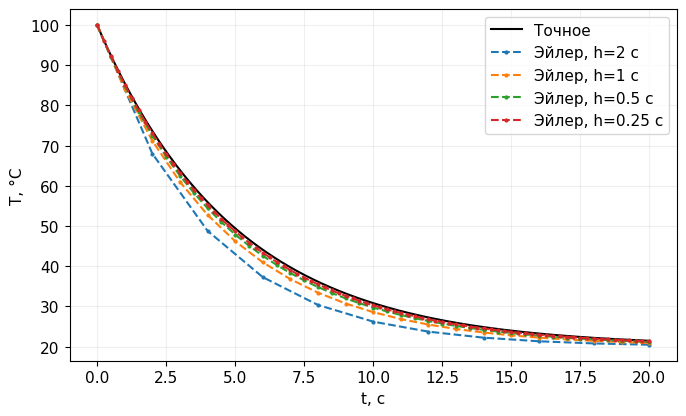

In [5]:
fig, ax = plt.subplots()
t_fine = np.linspace(0, 20, 400)
ax.plot(t_fine, exact_cooling(t_fine), color="black", label="Точное")
for dt in [2.0, 1.0, 0.5, 0.25]:
    t, T = euler_cooling(dt)
    ax.plot(t, T, "o--", markersize=2, label=f"Эйлер, h={dt:g} с")
ax.set(xlabel="t, с", ylabel="T, °C")
ax.legend(); fig.tight_layout(); plt.show()

## Четыре наклона RK4
Функция выполняет один шаг. Для всего интервала повторяем её в цикле.

## RK4 的四个斜率
函数完成一个时间步，在循环中调用即可求解整个时间区间。

In [6]:
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h*k1/2)
    k3 = f(t + h/2, y + h*k2/2)
    k4 = f(t + h, y + h*k3)
    return y + h/6 * (k1 + 2*k2 + 2*k3 + k4)

In [7]:
def rk4_cooling(dt, t_end=20.0):
    n_steps = round(t_end / dt)
    t = np.linspace(0, t_end, n_steps + 1)
    h = t[1] - t[0]
    T = np.empty_like(t)
    T[0] = T0
    for n in range(n_steps):
        T[n+1] = rk4_step(rhs_cooling, t[n], T[n], h)
    return t, T

In [8]:
t_rk4, T_rk4 = rk4_cooling(1.0)
print(f"T(20), RK4: {T_rk4[-1]:.10f} °C")
print(f"Ошибка в конце / 终点误差: {abs(T_rk4[-1]-exact_final):.3e} K")

T(20), RK4: 21.4653434695 °C
Ошибка в конце / 终点误差: 9.236e-05 K


## Порядок сходимости
Измеряем максимальную ошибку во всех узлах. При уменьшении шага вдвое ошибка Эйлера уменьшается примерно в 2 раза, RK4 — в 16 раз.

## 收敛阶
计算所有网格节点上的最大误差。步长减半时，欧拉法误差约减为一半，RK4 误差约减为 1/16。

In [9]:
steps = np.array([2.0, 1.0, 0.5, 0.25])
euler_errors, rk4_errors = [], []
for h in steps:
    t, T = euler_cooling(h)
    euler_errors.append(np.max(abs(T-exact_cooling(t))))
    t, T = rk4_cooling(h)
    rk4_errors.append(np.max(abs(T-exact_cooling(t))))
euler_errors = np.array(euler_errors)
rk4_errors = np.array(rk4_errors)
print("h       Эйлер / 欧拉      RK4")
for h, e1, e4 in zip(steps, euler_errors, rk4_errors):
    print(f"{h:4.2f}    {e1:12.5e}    {e4:12.5e}")
print("Порядок / 阶数, Euler:", np.log2(euler_errors[:-1]/euler_errors[1:]))
print("Порядок / 阶数, RK4:", np.log2(rk4_errors[:-1]/rk4_errors[1:]))

h       Эйлер / 欧拉      RK4
2.00     7.14632e+00     8.62318e-03
1.00     3.21596e+00     4.63756e-04
0.50     1.53608e+00     2.66593e-05
0.25     7.51482e-01     1.59809e-06
Порядок / 阶数, Euler: [1.15195259 1.06599392 1.03144394]
Порядок / 阶数, RK4: [4.21678121 4.12065694 4.06021948]


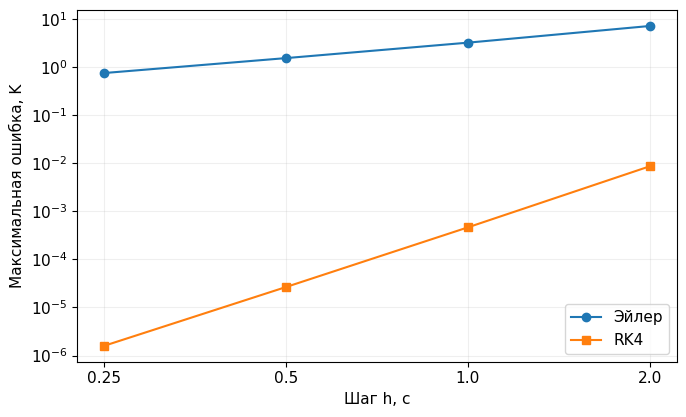

In [10]:
fig, ax = plt.subplots()
ax.loglog(steps, euler_errors, "o-", label="Эйлер")
ax.loglog(steps, rk4_errors, "s-", label="RK4")
ax.set(xlabel="Шаг h, с", ylabel="Максимальная ошибка, K")
ax.set_xticks(steps, [str(h) for h in steps])
ax.minorticks_off()
ax.legend(); fig.tight_layout(); plt.show()

## Устойчивость
Для $\theta=(T-T_\infty)/(T_0-T_\infty)$ схема даёт $\theta_{n+1}=(1-r)\theta_n$, где $r=k\Delta t$.
При $0<r<2$ амплитуда затухает; при $1<r<2$ знак чередуется. При $r=2$ колебания не затухают, при $r>2$ растут. При $r=1$ схема обнуляет $\theta$ за один шаг. Устойчивость не гарантирует точность.

## 稳定性
令 $r=k\Delta t$。当 $0<r<2$ 时幅值衰减，其中 $1<r<2$ 会出现交替振荡；$r=2$ 时等幅振荡；$r>2$ 时发散。$r=1$ 时数值解一步变为环境温度。稳定并不意味着准确。

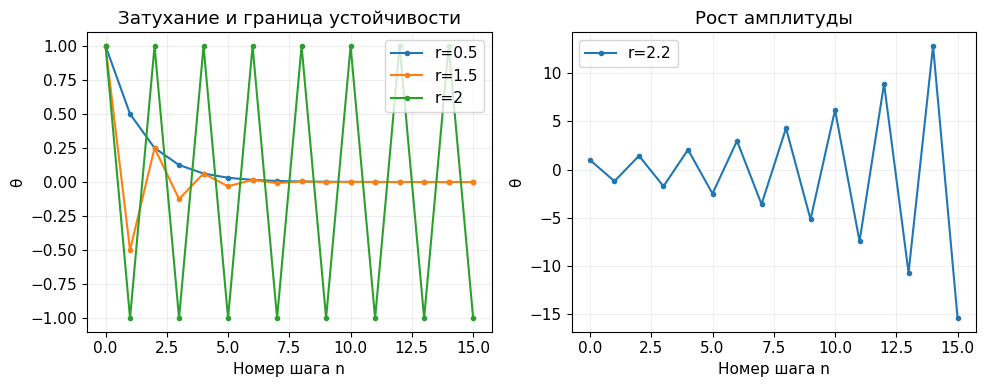

In [11]:
n = np.arange(16)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for r in [0.5, 1.5, 2.0, 2.2]:
    theta = np.empty(len(n)); theta[0] = 1.0
    for j in range(len(n)-1):
        theta[j+1] = (1-r)*theta[j]
    ax = axes[0] if r <= 2 else axes[1]
    ax.plot(n, theta, "o-", markersize=3, label=f"r={r:g}")
for ax in axes:
    ax.set(xlabel="Номер шага n", ylabel="θ")
    ax.legend()
axes[0].set_title("Затухание и граница устойчивости")
axes[1].set_title("Рост амплитуды")
fig.tight_layout(); plt.show()